In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Generate sample genomic data

rng = np.random.default_rng(42)

n_samples = 600

n_markers = 80


# Generate genetic marker values

X = rng.integers(
    0,
    3,
    size=(n_samples, n_markers)
)


# Generate class labels using selected markers

signal = (
    1.2 * X[:, 3] +
    1.0 * X[:, 11] +
    0.9 * X[:, 27] -
    1.1 * X[:, 42] +
    0.8 * X[:, 58] +
    rng.normal(0, 1.2, n_samples)
)


# Divide samples into two classes

y = (signal > np.median(signal)).astype(int)


# Create marker names

markers = [
    f"SNP_{i+1:03d}"
    for i in range(n_markers)
]


# Create DataFrame

df = pd.DataFrame(X, columns=markers)

df["Class"] = y


print("Genomic Dataset Created Successfully!")

display(df.head())

Genomic Dataset Created Successfully!


,SNP_001,SNP_002,SNP_003,SNP_004,SNP_005,SNP_006,SNP_007,SNP_008,SNP_009,SNP_010,...,SNP_072,SNP_073,SNP_074,SNP_075,SNP_076,SNP_077,SNP_078,SNP_079,SNP_080,Class
0,0,2,1,1,1,2,0,2,0,0,...,0,1,0,2,1,0,0,1,2,1
1,2,1,0,2,1,2,0,0,2,2,...,0,2,0,1,1,0,1,1,2,1
2,2,1,1,1,1,2,0,0,1,0,...,2,0,2,1,2,1,1,0,1,0
3,0,1,0,1,1,0,2,1,2,0,...,2,0,0,0,1,2,2,2,2,0
4,0,0,1,2,2,0,0,0,0,1,...,0,1,1,2,2,0,0,0,0,1


In [3]:
print("DATASET INFORMATION")

print("Total Samples:", len(df))

print("Total Markers:", len(markers))

print("Dataset Shape:", df.shape)


print("\nClass Distribution:")

print(df["Class"].value_counts())


print("\nMissing Values:")

print(df.isnull().sum().sum())


print("\nDataset Statistics:")

display(df[markers].describe().T.head(10))

DATASET INFORMATION
Total Samples: 600
Total Markers: 80
Dataset Shape: (600, 81)

Class Distribution:
Class
1    300
0    300
Name: count, dtype: int64

Missing Values:
0

Dataset Statistics:


,count,mean,std,min,25%,50%,75%,max
SNP_001,600.0,1.018333,0.822065,0.0,0.0,1.0,2.0,2.0
SNP_002,600.0,0.965000,0.821523,0.0,0.0,1.0,2.0,2.0
SNP_003,600.0,0.985000,0.834227,0.0,0.0,1.0,2.0,2.0
SNP_004,600.0,0.966667,0.814449,0.0,0.0,1.0,2.0,2.0
SNP_005,600.0,0.985000,0.822132,0.0,0.0,1.0,2.0,2.0
SNP_006,600.0,1.001667,0.826318,0.0,0.0,1.0,2.0,2.0
SNP_007,600.0,1.040000,0.822310,0.0,0.0,1.0,2.0,2.0
SNP_008,600.0,0.953333,0.819924,0.0,0.0,1.0,2.0,2.0
SNP_009,600.0,1.003333,0.817171,0.0,0.0,1.0,2.0,2.0
SNP_010,600.0,0.963333,0.818396,0.0,0.0,1.0,2.0,2.0


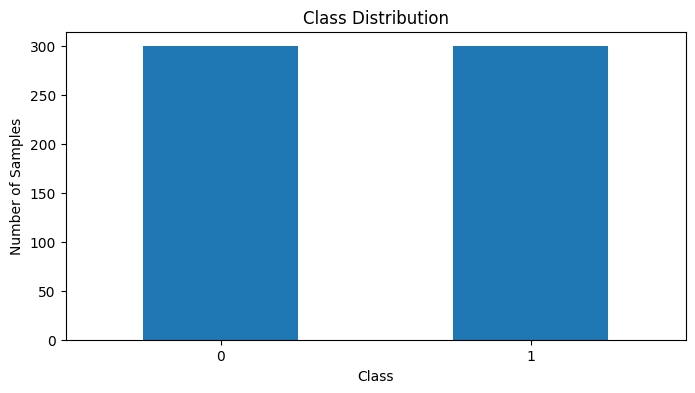

In [4]:
plt.figure(figsize=(8, 4))

df["Class"].value_counts().sort_index().plot(kind="bar")

plt.title("Class Distribution")

plt.xlabel("Class")

plt.ylabel("Number of Samples")

plt.xticks(rotation=0)

plt.show()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(

    df[markers],

    df["Class"],

    test_size=0.2,

    random_state=42,

    stratify=df["Class"]

)


print("Training Samples:", len(X_train))

print("Testing Samples:", len(X_test))

print("Training Data Shape:", X_train.shape)

print("Testing Data Shape:", X_test.shape)

Training Samples: 480
Testing Samples: 120
Training Data Shape: (480, 80)
Testing Data Shape: (120, 80)


In [6]:
# Create SVM model

svm = Pipeline([

    ("scaler", StandardScaler()),

    ("model", SVC(kernel="rbf", random_state=42))

])


# Train the model

svm.fit(X_train, y_train)


# Predict test data

svm_pred = svm.predict(X_test)


print("SVM Model Training Completed!")

print("\nSVM Classification Report:")

print(classification_report(y_test, svm_pred, digits=4))

SVM Model Training Completed!

SVM Classification Report:
              precision    recall  f1-score   support

           0     0.8214    0.7667    0.7931        60
           1     0.7812    0.8333    0.8065        60

    accuracy                         0.8000       120
   macro avg     0.8013    0.8000    0.7998       120
weighted avg     0.8013    0.8000    0.7998       120



In [7]:
# Create Random Forest model

rf = RandomForestClassifier(

    n_estimators=300,

    random_state=42,

    class_weight="balanced"

)


# Train the model

rf.fit(X_train, y_train)


# Predict test data

rf_pred = rf.predict(X_test)


print("Random Forest Training Completed!")

print("\nRandom Forest Classification Report:")

print(classification_report(y_test, rf_pred, digits=4))

Random Forest Training Completed!

Random Forest Classification Report:
              precision    recall  f1-score   support

           0     0.8226    0.8500    0.8361        60
           1     0.8448    0.8167    0.8305        60

    accuracy                         0.8333       120
   macro avg     0.8337    0.8333    0.8333       120
weighted avg     0.8337    0.8333    0.8333       120



In [8]:
# Function to calculate performance metrics

def metric_row(y, prediction):

    return [

        accuracy_score(y, prediction),

        precision_score(y, prediction, zero_division=0),

        recall_score(y, prediction, zero_division=0),

        f1_score(y, prediction, zero_division=0)

    ]


# Create comparison table

comparison = pd.DataFrame(

    [

        metric_row(y_test, svm_pred),

        metric_row(y_test, rf_pred)

    ],

    index=["SVM", "Random Forest"],

    columns=["Accuracy", "Precision", "Recall", "F1-Score"]

)


print("MODEL COMPARISON")

display(comparison.round(4))

MODEL COMPARISON


,Accuracy,Precision,Recall,F1-Score
SVM,0.8000,0.7812,0.8333,0.8065
Random Forest,0.8333,0.8448,0.8167,0.8305


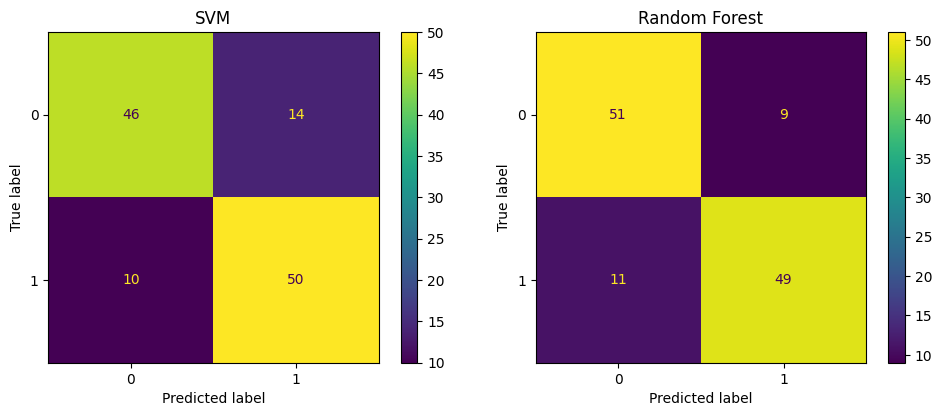

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))


# SVM confusion matrix

ConfusionMatrixDisplay.from_predictions(

    y_test,

    svm_pred,

    ax=ax[0]

)

ax[0].set_title("SVM")


# Random Forest confusion matrix

ConfusionMatrixDisplay.from_predictions(

    y_test,

    rf_pred,

    ax=ax[1]

)

ax[1].set_title("Random Forest")


plt.tight_layout()

plt.show()

In [10]:
# Calculate feature importance

importance = pd.Series(

    rf.feature_importances_,

    index=markers

)


# Sort markers by importance

importance = importance.sort_values(ascending=False)


print("TOP 15 IMPORTANT GENETIC MARKERS")

display(importance.head(15).to_frame("Importance"))

TOP 15 IMPORTANT GENETIC MARKERS


,Importance
SNP_004,0.078360
SNP_043,0.050903
SNP_028,0.045243
SNP_012,0.045013
SNP_059,0.023660
SNP_055,0.013357
SNP_005,0.013081
SNP_069,0.012067
SNP_031,0.011886
SNP_010,0.011783


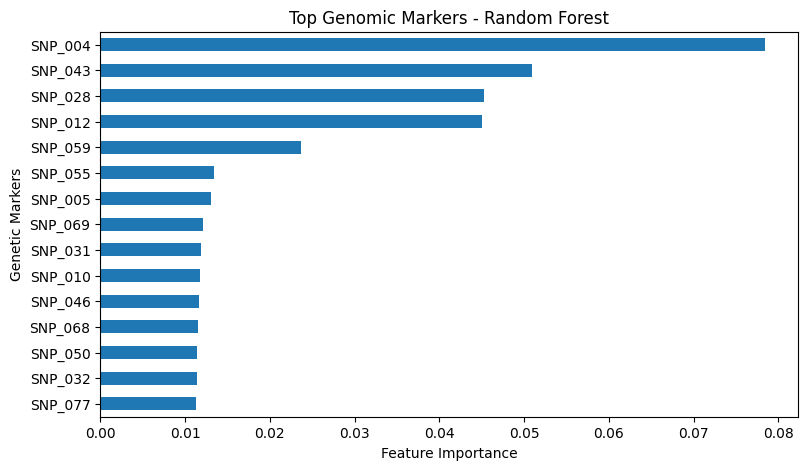

In [11]:
importance.head(15).sort_values().plot(

    kind="barh",

    figsize=(9, 5)

)


plt.title("Top Genomic Markers - Random Forest")

plt.xlabel("Feature Importance")

plt.ylabel("Genetic Markers")

plt.show()

In [12]:
print("=" * 50)

print("GENOMIC DATA CLASSIFICATION RESULTS")

print("=" * 50)


print("Total Samples:", len(df))

print("Total Genetic Markers:", len(markers))


print("\nSVM Accuracy:")

print(round(accuracy_score(y_test, svm_pred), 4))


print("\nRandom Forest Accuracy:")

print(round(accuracy_score(y_test, rf_pred), 4))


print("\nAnalysis Completed Successfully!")

print("=" * 50)

GENOMIC DATA CLASSIFICATION RESULTS
Total Samples: 600
Total Genetic Markers: 80

SVM Accuracy:
0.8

Random Forest Accuracy:
0.8333

Analysis Completed Successfully!
